## 01 - Visualization

**Imports and paths**

In [1]:
import io
import urllib.request
import zipfile
from pathlib import Path

import pandas as pd

DATA_DIR = Path("../data")
DATA_PATH = DATA_DIR / "Patient_Health_Records_Raw.csv"
DATASET_URL = "https://www.kaggle.com/api/v1/datasets/download/mursaleen880/patient-health-record-raw-csv"

**Download dataset**

In [2]:
if not DATA_PATH.exists():
    with urllib.request.urlopen(DATASET_URL) as response:
        zipfile.ZipFile(io.BytesIO(response.read())).extract(DATA_PATH.name, DATA_DIR)

**Load data**

In [3]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head(10)

(10000, 17)


,Patient_ID,Name,Age,Gender,City,BMI,Blood_Pressure,Heart_Rate,Cholesterol_Level,Diabetic,Smoker,Medications,Last_Visit_Date,Follow_Up,Diagnosis_Code,Notes,Has_Disease
0,ID-00001,"SMITH, ALICE",250,Unknown,Boston,22kg/m2,120 over 80,83,190,Unknown,yes,NaN,Apr 15 2021,30,A00,Patient feeling fine 🙂,0
1,ID-00002,"SMITH, ALICE",-5,FEMALE,newyork,25.8,NaN,500,normal,N,No,NaN,2021-07-10,NaN,unknown,"BP high, needs recheck",unknown
2,ID-00003,John Doe,-5,NaN,Nwe Yrok,22kg/m2,120 - 80,500,190,no,Former,"aspirin,metformin",Apr 06 2021,30,B20,NaN,unknown
3,ID-00004,michael brown,80,F,New York,33.4,NaN,eighty,250,y,EX-smoker,NaN,20241113,30,NaN,Follow up soon,unknown
4,ID-00005,Jane Doe,250,male,la,30.1,120 over 80,0,normal,no,No,NaN,2025-09-27,NaN,I10,Patient feeling fine 🙂,1
5,ID-00006,michael brown,-5,Unknown,NaN,22kg/m2,120 - 80,63,normal,no,EX-smoker,NaN,2025-05-22,30,E11.9,NaN,0
6,ID-00007,"LEE, Sara",98,M,Chicago,NaN,120 over 80,108,normal,Unknown,No,"aspirin,metformin",09/03/2024,NaN,E11.9,Follow up soon,unknown
7,ID-00008,"SMITH, ALICE",250,M,New York,22.5,120 over 80,85,250,y,NaN,NaN,May 22 2022,NaN,I10,"BP high, needs recheck",unknown
8,ID-00009,John Doe,250,NaN,Boston,NaN,120 over 80,500,high,N,Former,Aspirin; Metformin,02/03/2020,30,unknown,NaN,0
9,ID-00010,michael brown,-5,Unknown,Chicago,21.5,NaN,eighty,NaN,no,Former,NaN,2025-03-30,30,A00,"BP high, needs recheck",1


**Data types**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Patient_ID         9493 non-null   object
 1   Name               10000 non-null  object
 2   Age                10000 non-null  object
 3   Gender             8293 non-null   object
 4   City               8997 non-null   object
 5   BMI                7582 non-null   object
 6   Blood_Pressure     7970 non-null   object
 7   Heart_Rate         10000 non-null  object
 8   Cholesterol_Level  7948 non-null   object
 9   Diabetic           8359 non-null   object
 10  Smoker             6766 non-null   object
 11  Medications        5976 non-null   object
 12  Last_Visit_Date    10000 non-null  object
 13  Follow_Up          7476 non-null   object
 14  Diagnosis_Code     8325 non-null   object
 15  Notes              5976 non-null   object
 16  Has_Disease        7480 non-null   object

In [5]:
pd.DataFrame({
    "dtype": df.dtypes,
    "sample_values": [df[c].dropna().unique()[:5].tolist() for c in df.columns],
})

,dtype,sample_values
Patient_ID,object,"[ID-00001, ID-00002, ID-00003, ID-00004, ID-00..."
Name,object,"[SMITH, ALICE, John Doe, michael brown, Jane ..."
Age,object,"[250, -5, 80, 98, twenty]"
Gender,object,"[Unknown, FEMALE, F, male, M]"
City,object,"[Boston, newyork, Nwe Yrok, New York, la]"
BMI,object,"[22kg/m2, 25.8, 33.4, 30.1, 22.5]"
Blood_Pressure,object,"[120 over 80, 120 - 80, 120/80, 115/61, 106/68]"
Heart_Rate,object,"[83, 500, eighty, 0, 63]"
Cholesterol_Level,object,"[190, normal, 250, high]"
Diabetic,object,"[Unknown, N, no, y, Yes]"


**Null values**

In [6]:
nulls = pd.DataFrame({
    "null_count": df.isna().sum(),
    "null_pct": (df.isna().mean() * 100).round(2),
}).sort_values("null_count", ascending=False)
nulls

,null_count,null_pct
Notes,4024,40.24
Medications,4024,40.24
Smoker,3234,32.34
Follow_Up,2524,25.24
Has_Disease,2520,25.20
BMI,2418,24.18
Cholesterol_Level,2052,20.52
Blood_Pressure,2030,20.30
Gender,1707,17.07
Diagnosis_Code,1675,16.75


**Disguised missing values**

In [7]:
MISSING_TOKENS = {"", "unknown", "n/a", "na", "nan", "null", "none", "?", "-"}

def is_disguised_missing(s: pd.Series) -> pd.Series:
    return s.notna() & s.astype(str).str.strip().str.lower().isin(MISSING_TOKENS)

disguised = pd.DataFrame({
    "disguised_count": df.apply(lambda s: is_disguised_missing(s).sum()),
    "tokens_found": df.apply(lambda s: sorted(s[is_disguised_missing(s)].astype(str).unique())),
})
disguised["total_missing"] = disguised["disguised_count"] + df.isna().sum()
disguised["total_missing_pct"] = (disguised["total_missing"] / len(df) * 100).round(2)
disguised.sort_values("total_missing", ascending=False)

,disguised_count,tokens_found,total_missing,total_missing_pct
Has_Disease,2506,[unknown],5026,50.26
Notes,0,[],4024,40.24
Medications,0,[],4024,40.24
Gender,1719,[Unknown],3426,34.26
Diagnosis_Code,1691,[unknown],3366,33.66
Diabetic,1660,[Unknown],3301,33.01
Smoker,0,[],3234,32.34
Follow_Up,0,[],2524,25.24
BMI,0,[],2418,24.18
Cholesterol_Level,0,[],2052,20.52


**Duplicate rows**

In [8]:
non_id_cols = [c for c in df.columns if c != "Patient_ID"]

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate rows ignoring Patient_ID:", df.duplicated(subset=non_id_cols).sum())
print("Duplicate non-null Patient_IDs:", df["Patient_ID"].dropna().duplicated().sum())

Exact duplicate rows: 0
Duplicate rows ignoring Patient_ID: 0
Duplicate non-null Patient_IDs: 0


**Unique values per column**

In [9]:
pd.DataFrame({
    "n_unique": df.nunique(dropna=False),
    "n_unique_normalized": df.apply(lambda s: s.astype(str).str.strip().str.lower().nunique()),
}).sort_values("n_unique")

,n_unique,n_unique_normalized
Follow_Up,4,4
Notes,4,4
Medications,4,4
Has_Disease,4,4
Cholesterol_Level,5,5
Smoker,5,5
Name,5,5
Diabetic,6,6
Diagnosis_Code,6,6
Gender,6,6


In [10]:
for col in df.columns:
    if df[col].nunique(dropna=False) <= 20:
        print(f"--- {col} ---")
        print(df[col].value_counts(dropna=False).to_string(), end="\n\n")

--- Name ---
Name
LEE, Sara         2038
SMITH, ALICE      2015
 michael brown    2008
John Doe          1975
Jane  Doe         1964

--- Gender ---
Gender
Unknown    1719
NaN        1707
male       1703
FEMALE     1679
M          1607
F          1585

--- City ---
City
Chicago        1048
NY             1045
Boston         1023
la             1010
NaN            1003
New York       1003
Nwe Yrok        992
newyork         974
chicago         971
Los Angeles     931

--- Cholesterol_Level ---
Cholesterol_Level
NaN       2052
190       2048
normal    1994
250       1970
high      1936

--- Diabetic ---
Diabetic
no         1721
Yes        1689
Unknown    1660
N          1651
NaN        1641
y          1638

--- Smoker ---
Smoker
NaN          3234
EX-smoker    1739
Former       1718
No           1663
yes          1646

--- Medications ---
Medications
NaN                       4024
aspirin,metformin         2011
Lisinopril / Metformin    2011
Aspirin; Metformin        1954

--- Follow_Up -

**Numeric parseability and ranges**

In [11]:
NUMERIC_COLS = ["Age", "BMI", "Heart_Rate", "Cholesterol_Level", "Follow_Up"]

parsed = df[NUMERIC_COLS].apply(pd.to_numeric, errors="coerce")
unparseable = df[NUMERIC_COLS].notna() & parsed.isna()

pd.DataFrame({
    "unparseable_count": unparseable.sum(),
    "unparseable_examples": [sorted(df.loc[unparseable[c], c].astype(str).unique())[:5] for c in NUMERIC_COLS],
})

,unparseable_count,unparseable_examples
Age,2489,[twenty]
BMI,2467,[22kg/m2]
Heart_Rate,2459,[eighty]
Cholesterol_Level,3930,"[high, normal]"
Follow_Up,2540,[two weeks]


In [12]:
parsed.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,7511.0,95.713753,110.017237,-5.0,-5.0,48.0,250.0,250.0
BMI,5115.0,23.691300,4.194107,15.0,22.5,22.5,24.7,35.0
Heart_Rate,7541.0,195.882376,218.275943,0.0,0.0,87.0,500.0,500.0
Cholesterol_Level,4018.0,219.417621,29.998080,190.0,190.0,190.0,250.0,250.0
Follow_Up,4936.0,22.019449,8.000787,14.0,14.0,30.0,30.0,30.0


**Target distribution**

In [13]:
df["Has_Disease"].value_counts(dropna=False)

Has_Disease
NaN        2520
0          2513
unknown    2506
1          2461
Name: count, dtype: int64

**1.1 Data quality overview**

In [14]:
import re

import matplotlib.pyplot as plt

FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)

VALID, INVALID, NULL, TEXT = "valid", "invalid", "null", "unparseable text"
NULL_TOKENS = {"", "unknown", "n/a", "na", "nan", "null"}
NUMBER_PATTERN = re.compile(r"-?\d+(\.\d+)?")
BP_PATTERN = re.compile(r"(\d+)\s*(?:/|over|-)\s*(\d+)")


def classify_number(value, low, high, unit="", integer=False):
    v = value.strip().lower()
    if v in NULL_TOKENS:
        return NULL
    v = v.removesuffix(unit).strip()
    if not NUMBER_PATTERN.fullmatch(v):
        return TEXT
    number = float(v)
    if integer and not number.is_integer():
        return INVALID
    return VALID if low <= number <= high else INVALID


def classify_blood_pressure(value):
    v = value.strip().lower()
    if v in NULL_TOKENS:
        return NULL
    match = BP_PATTERN.fullmatch(v)
    if not match:
        return TEXT
    systolic, diastolic = map(int, match.groups())
    in_range = 70 <= systolic <= 250 and 40 <= diastolic <= 150 and systolic > diastolic
    return VALID if in_range else INVALID


def classify_category(value):
    return NULL if value.strip().lower() in NULL_TOKENS else VALID


NUMERIC_RULES = {
    "Age": lambda v: classify_number(v, 0, 120, integer=True),
    "BMI": lambda v: classify_number(v, 10, 70, unit="kg/m2"),
    "Heart_Rate": lambda v: classify_number(v, 30, 220),
    "Blood_Pressure": classify_blood_pressure,
    "Cholesterol_Level": lambda v: classify_number(v, 100, 400),
    "Follow_Up": lambda v: classify_number(v, 1, float("inf")),
}
CATEGORICAL_RULES = {
    col: classify_category
    for col in ["Gender", "City", "Diabetic", "Smoker", "Medications", "Diagnosis_Code", "Notes", "Has_Disease"]
}

In [15]:
def quality_shares(rules):
    labels = pd.DataFrame({col: raw[col].map(rule) for col, rule in rules.items()})
    shares = labels.apply(lambda s: s.value_counts(normalize=True)).T * 100
    return shares.reindex(columns=[VALID, INVALID, NULL, TEXT]).fillna(0)


numeric_quality = quality_shares(NUMERIC_RULES)
categorical_quality = quality_shares(CATEGORICAL_RULES)[[VALID, NULL]]
pd.concat({"numeric": numeric_quality, "categorical": categorical_quality}).round(1)

valid  invalid  null  unparseable text
numeric     Age                 25.6     49.6   0.0              24.9
            BMI                 75.8      0.0  24.2               0.0
            Heart_Rate          25.7     49.7   0.0              24.6
            Blood_Pressure      79.1      0.6  20.3               0.0
            Cholesterol_Level   40.2      0.0  20.5              39.3
            Follow_Up           49.4      0.0  25.2              25.4
categorical Gender              65.7      NaN  34.3               NaN
            City                90.0      NaN  10.0               NaN
            Diabetic            67.0      NaN  33.0               NaN
            Smoker              67.7      NaN  32.3               NaN
            Medications         79.5      NaN  20.5               NaN
            Diagnosis_Code      66.3      NaN  33.7               NaN
            Notes               59.8      NaN  40.2               NaN
            Has_Disease         49.7      NaN  50.3               NaN

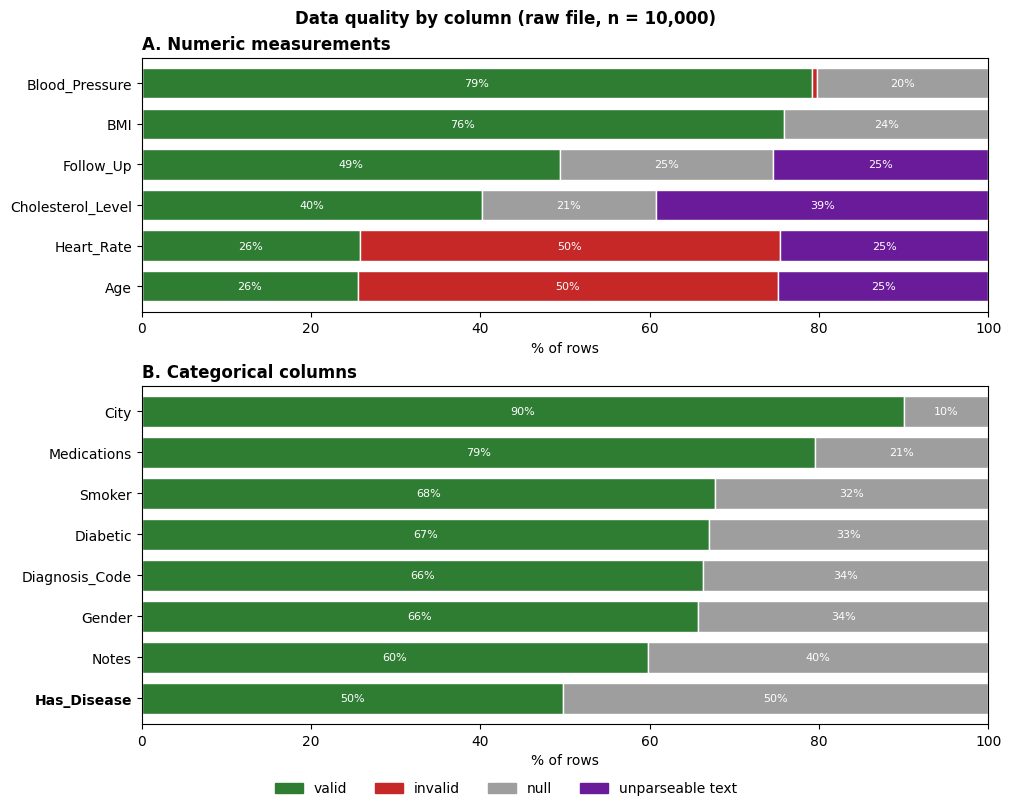

In [16]:
COLORS = {VALID: "#2e7d32", INVALID: "#c62828", NULL: "#9e9e9e", TEXT: "#6a1b9a"}
panels = [
    (numeric_quality, "A. Numeric measurements"),
    (categorical_quality, "B. Categorical columns"),
]

fig, axes = plt.subplots(
    2, 1, figsize=(10, 8), layout="constrained",
    gridspec_kw={"height_ratios": [len(numeric_quality), len(categorical_quality)]},
)
for ax, (shares, title) in zip(axes, panels):
    shares = shares.sort_values(VALID)
    shares.plot.barh(stacked=True, ax=ax, width=0.75, edgecolor="white",
                     color=[COLORS[c] for c in shares.columns], legend=False)
    for container in ax.containers:
        ax.bar_label(container, label_type="center", color="white", fontsize=8,
                     labels=[f"{w:.0f}%" if w >= 4 else "" for w in container.datavalues])
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of rows")
    ax.set_ylabel("")

for label in axes[1].get_yticklabels():
    if label.get_text() == "Has_Disease":
        label.set_fontweight("bold")

handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[k]) for k in COLORS]
fig.legend(handles, COLORS.keys(), loc="outside lower center", ncol=4, frameon=False)
fig.suptitle(f"Data quality by column (raw file, n = {len(raw):,})", fontweight="bold")
fig.savefig(FIGURES_DIR / "01_data_quality_overview.png", dpi=150, bbox_inches="tight")
plt.show()

**Columns excluded from the chart**

In [17]:
DATE_FORMATS = ["%Y-%m-%d", "%d/%m/%Y", "%b %d %Y", "%Y%m%d"]
visit_dates = (
    pd.concat([pd.to_datetime(raw["Last_Visit_Date"], format=f, errors="coerce") for f in DATE_FORMATS], axis=1)
    .bfill(axis=1)
    .iloc[:, 0]
)

print(f"Patient_ID: {(raw['Patient_ID'].str.strip() == '').sum()} blank rows")
print(f"Name: {raw['Name'].nunique()} distinct values")
print(f"Last_Visit_Date: {visit_dates.isna().sum()} unparseable, range {visit_dates.min():%Y-%m-%d} to {visit_dates.max():%Y-%m-%d}")

Patient_ID: 507 blank rows
Name: 5 distinct values
Last_Visit_Date: 0 unparseable, range 2020-01-01 to 2025-10-01


**1.2 Target distribution**

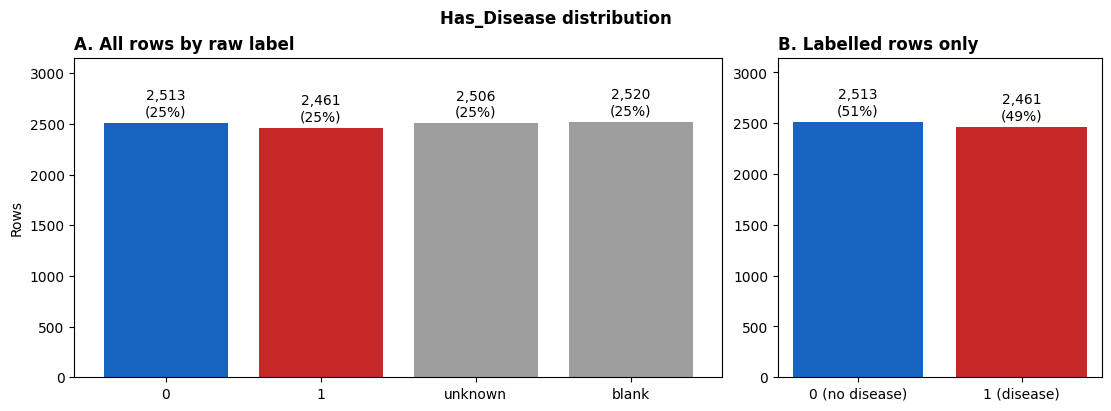

In [18]:
target_raw = raw["Has_Disease"].str.strip().replace({"": "blank"})
target_counts = target_raw.value_counts().reindex(["0", "1", "unknown", "blank"])
labelled = raw[target_raw.isin(["0", "1"])].copy()
labelled["target"] = labelled["Has_Disease"].astype(int)

fig, (ax_all, ax_lab) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained",
                                     gridspec_kw={"width_ratios": [2, 1]})
ax_all.bar(target_counts.index, target_counts.values,
           color=["#1565c0", "#c62828", "#9e9e9e", "#9e9e9e"])
ax_all.bar_label(ax_all.containers[0], padding=3, labels=[f"{n:,}\n({n / len(raw):.0%})" for n in target_counts])
ax_all.set_title("A. All rows by raw label", loc="left", fontweight="bold")
ax_all.set_ylabel("Rows")
ax_all.set_ylim(0, target_counts.max() * 1.25)

class_counts = labelled["target"].value_counts().sort_index()
ax_lab.bar(["0 (no disease)", "1 (disease)"], class_counts.values, color=["#1565c0", "#c62828"])
ax_lab.bar_label(ax_lab.containers[0], padding=3, labels=[f"{n:,}\n({n / len(labelled):.0%})" for n in class_counts])
ax_lab.set_title("B. Labelled rows only", loc="left", fontweight="bold")
ax_lab.set_ylim(0, class_counts.max() * 1.25)

fig.suptitle("Has_Disease distribution", fontweight="bold")
fig.savefig(FIGURES_DIR / "02_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Disease rate helpers**

In [19]:
OVERALL_RATE = labelled["target"].mean()


def disease_rate(groups: pd.Series) -> pd.DataFrame:
    stats = labelled.groupby(groups)["target"].agg(n="size", rate="mean")
    se = (stats["rate"] * (1 - stats["rate"]) / stats["n"]) ** 0.5
    stats["ci95"] = 1.96 * se
    return stats.sort_values("rate")


def plot_rate(ax, stats, title):
    ax.barh(stats.index, stats["rate"] * 100, xerr=stats["ci95"] * 100,
            color="#5c6bc0", ecolor="#424242", capsize=3)
    ax.axvline(OVERALL_RATE * 100, color="#c62828", linestyle="--", linewidth=1)
    for y, (rate, n) in enumerate(zip(stats["rate"], stats["n"])):
        ax.text(1, y, f"{rate:.0%}  (n={n:,})", va="center", color="white", fontsize=8)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlim(0, 100)
    ax.set_xlabel("% with disease")

**1.3 Leakage check**

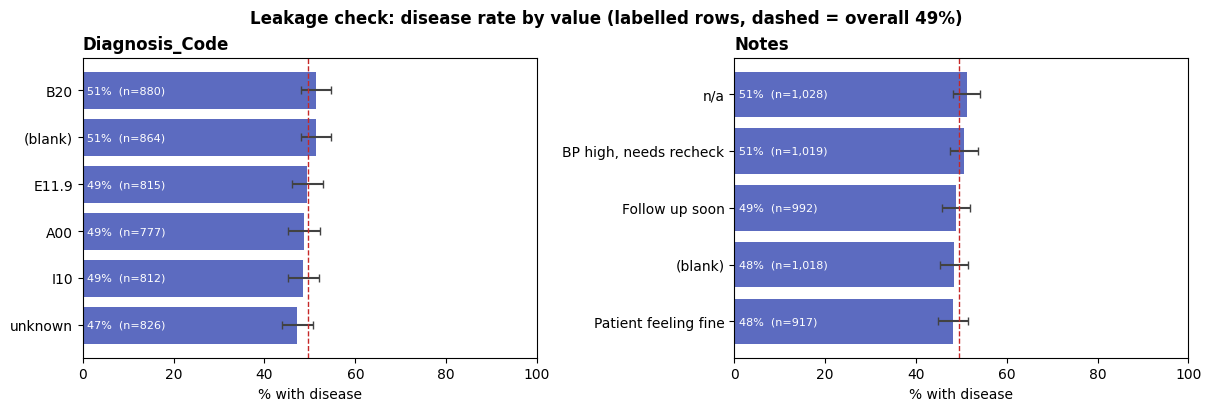

In [20]:
leakage_cols = ["Diagnosis_Code", "Notes"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, col in zip(axes, leakage_cols):
    groups = labelled[col].str.encode("ascii", "ignore").str.decode("ascii").str.strip().replace({"": "(blank)"})
    plot_rate(ax, disease_rate(groups), col)

fig.suptitle(f"Leakage check: disease rate by value (labelled rows, dashed = overall {OVERALL_RATE:.0%})",
             fontweight="bold")
fig.savefig(FIGURES_DIR / "03_leakage_check.png", dpi=150, bbox_inches="tight")
plt.show()

**1.4 Disease rate by category**

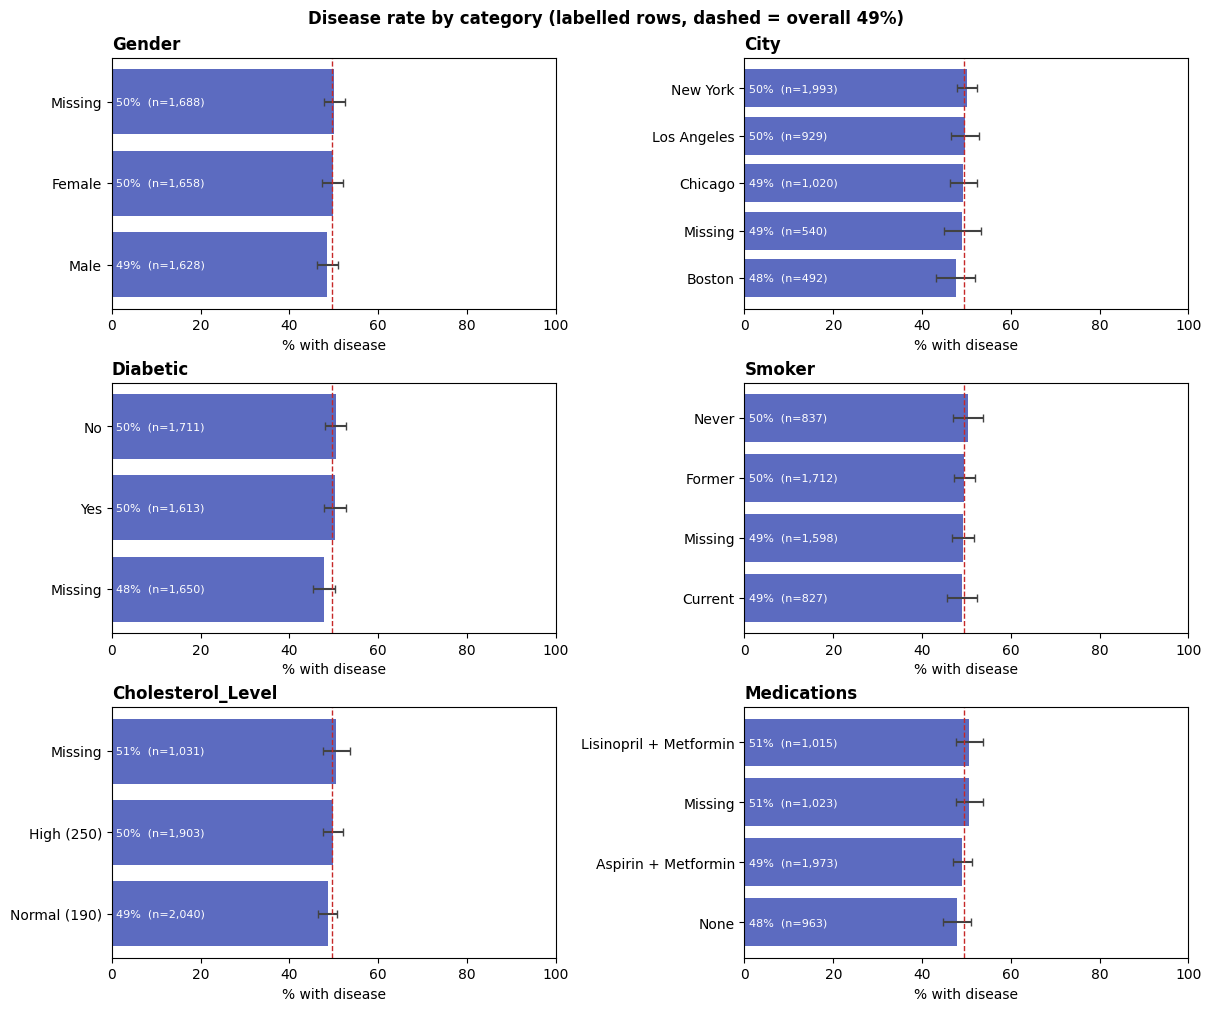

In [21]:
CATEGORY_MAPS = {
    "Gender": {"male": "Male", "m": "Male", "female": "Female", "f": "Female"},
    "City": {"chicago": "Chicago", "boston": "Boston", "ny": "New York", "new york": "New York",
             "newyork": "New York", "nwe yrok": "New York", "la": "Los Angeles", "los angeles": "Los Angeles"},
    "Diabetic": {"yes": "Yes", "y": "Yes", "no": "No", "n": "No"},
    "Smoker": {"yes": "Current", "ex-smoker": "Former", "former": "Former", "no": "Never"},
    "Cholesterol_Level": {"190": "Normal (190)", "normal": "Normal (190)", "250": "High (250)", "high": "High (250)"},
    "Medications": {"none": "None", "aspirin,metformin": "Aspirin + Metformin",
                    "aspirin; metformin": "Aspirin + Metformin", "lisinopril / metformin": "Lisinopril + Metformin"},
}


def normalize(col):
    return labelled[col].str.strip().str.lower().map(CATEGORY_MAPS[col]).fillna("Missing")


fig, axes = plt.subplots(3, 2, figsize=(12, 10), layout="constrained")
for ax, col in zip(axes.flat, CATEGORY_MAPS):
    plot_rate(ax, disease_rate(normalize(col)), col)

fig.suptitle(f"Disease rate by category (labelled rows, dashed = overall {OVERALL_RATE:.0%})", fontweight="bold")
fig.savefig(FIGURES_DIR / "04_disease_rate_by_category.png", dpi=150, bbox_inches="tight")
plt.show()